# IN4190 - project

In [ ]:
#For parsing and general analysis
import numpy as np
import matplotlib.pyplot as plt
import h5py
import os

#For datetime objects
from matplotlib import dates
from datetime import datetime, timedelta
import dateutil.parser

#For map
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from geopy.distance import great_circle

In [ ]:
# Set path for data
path = os.path.abspath('.') + '/' #Working directory path (Where program is run from)
fn_list = os.listdir(path + '/project_data') #List of all file names
print(fn_list)

['AM.R0033_unfilt.h5', 'AM.R0318_unfilt.h5', 'AM.R0352_unfilt.h5', 'AM.R03EA_unfilt.h5', 'AM.R06C4_unfilt.h5', 'AM.R06CE_unfilt.h5', 'AM.R0835_unfilt.h5', 'AM.R08DA_unfilt.h5', 'AM.R095E_unfilt.h5', 'AM.R0C1F_unfilt.h5', 'AM.R1033_unfilt.h5', 'AM.R10D3_unfilt.h5', 'AM.R10DB_unfilt.h5', 'AM.R13D2_unfilt.h5', 'AM.R160F_unfilt.h5', 'AM.R167F_unfilt.h5', 'AM.R176D_unfilt.h5', 'AM.R17FC_unfilt.h5', 'AM.R18EB_unfilt.h5', 'AM.R1936_unfilt.h5', 'AM.R199D_unfilt.h5', 'AM.R216B_unfilt.h5', 'AM.R25AC_unfilt.h5', 'AM.R25D6_unfilt.h5', 'AM.R266F_unfilt.h5', 'AM.R2883_unfilt.h5', 'AM.R2BFC_unfilt.h5', 'AM.R2C45_unfilt.h5', 'AM.R2D80_unfilt.h5', 'AM.R2DDD_unfilt.h5', 'AM.R2FF1_unfilt.h5', 'AM.R3333_unfilt.h5', 'AM.R3412_unfilt.h5', 'AM.R347E_unfilt.h5', 'AM.R3609_unfilt.h5', 'AM.R3635_unfilt.h5', 'AM.R3740_unfilt.h5', 'AM.R3786_unfilt.h5', 'AM.R3812_unfilt.h5', 'AM.R39A8_unfilt.h5', 'AM.R3A9B_unfilt.h5', 'AM.R3F75_unfilt.h5', 'AM.R40C1_unfilt.h5', 'AM.R438F_unfilt.h5', 'AM.R44DC_unfilt.h5', 'AM.R45FA

In [ ]:
h1 = [9.3102e-04,
  -1.2991e-18,
  -1.1771e-03,
  -8.9350e-04,
   1.1279e-03,
   2.3259e-03,
  -3.0497e-18,
  -3.7419e-03,
  -2.8954e-03,
   3.5886e-03,
   7.1273e-03,
  -6.7002e-18,
  -1.0473e-02,
  -7.7679e-03,
   9.2793e-03,
   1.7882e-02,
  -1.0958e-17,
  -2.5342e-02,
  -1.8731e-02,
   2.2575e-02,
   4.4596e-02,
  -1.4316e-17,
  -7.1659e-02,
  -6.0472e-02,
   9.2253e-02,
   3.0157e-01,
   3.9980e-01,
   3.0157e-01,
   9.2253e-02,
  -6.0472e-02,
  -7.1659e-02,
  -1.4316e-17,
   4.4596e-02,
   2.2575e-02,
  -1.8731e-02,
  -2.5342e-02,
  -1.0958e-17,
   1.7882e-02,
   9.2793e-03,
  -7.7679e-03,
  -1.0473e-02,
  -6.7002e-18,
   7.1273e-03,
   3.5886e-03,
  -2.8954e-03,
  -3.7419e-03,
  -3.0497e-18,
   2.3259e-03,
   1.1279e-03,
  -8.9350e-04,
  -1.1771e-03,
  -1.2991e-18,
   9.3102e-04,
]

h2 = [6.8867e-04,
  -1.0409e-18,
  -8.7071e-04,
  -1.6144e-04,
   2.4454e-03,
   4.3979e-03,
   2.9653e-03,
   1.8510e-04,
   1.9464e-03,
   9.1274e-03,
   1.2922e-02,
   5.3683e-03,
  -6.4293e-03,
  -6.1213e-03,
   7.3124e-03,
   1.0978e-02,
  -1.3170e-02,
  -4.5946e-02,
  -4.7642e-02,
  -1.5176e-02,
  -2.2060e-03,
  -5.5677e-02,
  -1.3549e-01,
  -1.3111e-01,
   1.6668e-02,
   2.2307e-01,
   3.2035e-01,
   2.2307e-01,
   1.6668e-02,
  -1.3111e-01,
  -1.3549e-01,
  -5.5677e-02,
  -2.2060e-03,
  -1.5176e-02,
  -4.7642e-02,
  -4.5946e-02,
  -1.3170e-02,
   1.0978e-02,
   7.3124e-03,
  -6.1213e-03,
  -6.4293e-03,
   5.3683e-03,
   1.2922e-02,
   9.1274e-03,
   1.9464e-03,
   1.8510e-04,
   2.9653e-03,
   4.3979e-03,
   2.4454e-03,
  -1.6144e-04,
  -8.7071e-04,
  -1.0409e-18,
   6.8867e-04,
]

h3 = [-2.4366e-04,
  -2.6135e-19,
   3.0807e-04,
   7.3294e-04,
   1.3147e-03,
   2.0667e-03,
   2.9630e-03,
   3.9300e-03,
   4.8428e-03,
   5.5289e-03,
   5.7792e-03,
   5.3643e-03,
   4.0571e-03,
   1.6578e-03,
  -1.9803e-03,
  -6.9275e-03,
  -1.3160e-02,
  -2.0549e-02,
  -2.8859e-02,
  -3.7759e-02,
  -4.6838e-02,
  -5.5636e-02,
  -6.3672e-02,
  -7.0487e-02,
  -7.5676e-02,
  -7.8923e-02,
   9.2033e-01,
  -7.8923e-02,
  -7.5676e-02,
  -7.0487e-02,
  -6.3672e-02,
  -5.5636e-02,
  -4.6838e-02,
  -3.7759e-02,
  -2.8859e-02,
  -2.0549e-02,
  -1.3160e-02,
  -6.9275e-03,
  -1.9803e-03,
   1.6578e-03,
   4.0571e-03,
   5.3643e-03,
   5.7792e-03,
   5.5289e-03,
   4.8428e-03,
   3.9300e-03,
   2.9630e-03,
   2.0667e-03,
   1.3147e-03,
   7.3294e-04,
   3.0807e-04,
  -2.6135e-19,
  -2.4366e-04,
]
print(np.shape(h1))

(53,)


## Functions

In [ ]:
def parse(num_files=None):
    #Read files and store contents. Accepts user input for number of files to read.
    if num_files:
        N_files = num_files
    else:
        N_files = len(fn_list)

    # Initialize
    lats = np.zeros(N_files)
    lons = np.zeros(N_files)
    dt = np.zeros(N_files)

    N_samples = 720000 #Size of the datasets in the files. Hard coded unless you want dynamic allocation (lists, slower)
    data_collection = np.zeros((N_files,N_samples)) # all station data
    times_collection = np.zeros((N_files,N_samples), dtype=datetime) # all correponding time vectors


    #Loop over files
    for ii in range(N_files):
        if (ii%50) == 0:
            print('Loading station ' , ii, ' out of ' , N_files-1)

        this_fn = h5py.File(path + 'project_data/' + fn_list[ii], 'r') # The file path we will read

        # Read the latitude and longitude attributes for the station and put into vectors
        lats[ii] = this_fn.attrs['latitude']
        lons[ii] = this_fn.attrs['longitude']

        #Read tree structure and load dataset into aggregate array
        level1 = list(this_fn.keys()) # /waveforms
        level2 = list(this_fn[level1[0]].keys()) # /waveforms/dataset_name
        dataset = this_fn['/' + level1[0] + '/' + level2[0]] #Reading dataset in subgroup
        data = dataset[:] #Extract numpy array from dataset object

        #If missing data, pad with zeros
        if len(data) < N_samples:
            #data = np.pad(data, (0, N_samples-len(data)), 'constant', constant_values=np.nan)
            data = np.pad(data, (0, N_samples-len(data)), 'constant', constant_values=0)

        data_collection[ii,:] = data #Loading numpy array into aggregate data array

        # Figure out the start time and generate a time vector
        start_time_str = dataset.attrs['starttime']
        start_time = dateutil.parser.isoparse(start_time_str) #Time attribute on ISO-format

        dt[ii] = dataset.attrs['delta']
        deltas = np.linspace(0, dt[ii]*(N_samples-1), N_samples) #A duration which can be added to a datetime object
        times = start_time + deltas*timedelta(seconds = 1)
        times_collection[ii,:] = times #Loading times into aggregate array

    print('done')
    return data_collection, times_collection, lats, lons, dt

In [ ]:
def plot_map(lats, lons, tonga_latlon):
    northward_offset = 90 #As in sample program
    central_lat = tonga_latlon[0] + northward_offset
    central_lon = tonga_latlon[1]

    fig = plt.figure(figsize=(15, 15))
    ax = fig.add_subplot(1, 1, 1, 
    projection=ccrs.AzimuthalEquidistant(central_latitude = central_lat, central_longitude=central_lon))

    #Stock background (Natural Earth)
    ax.stock_img()

    #Add features on top of stock_img for better resolution 
    ax.add_feature(cfeature.LAND, alpha=0.5, zorder=1)
    ax.add_feature(cfeature.COASTLINE, linewidth=0.3, zorder=1)
    ax.add_feature(cfeature.BORDERS, linestyle=':', linewidth=0.3, alpha=1, zorder=1)

    #Make the map global rather than have it zoom in to the extents of any plotted data
    ax.set_global()
    
    #Make gridlines
    ax.gridlines(crs=ccrs.PlateCarree())

    #Plot stations and Hunga Tonga
    ax.scatter(tonga_latlon[1], tonga_latlon[0], marker = 'x', linewidth = 2, 
    color='red', transform=ccrs.PlateCarree()) #Transform is PlateCarree regardless of projection

    ax.scatter(lons, lats, marker = '^', linewidth = 0.5, facecolor='none', 
    edgecolor='magenta', transform=ccrs.PlateCarree()) #Transform is PlateCarree regardless of projection

    plt.show()


def circle_distance(n_files, lats, lons, tonga_latlon):
    #Calculate great circle distance. Using geopy.great_circle
    dists = []
    for i in range(n_files):
        dists.append(great_circle((tonga_latlon[0], tonga_latlon[1]) , (lats[i], lons[i])).m)
        
    dists = np.array(dists)
    dists_km = dists/1000
    
    print('Smallest great cricle distance is {:.2f}km. Largest great circle distance is {:.2f}km'.format(
        np.min(dists_km), np.max(dists_km)))
    
    #plt.style.use('whitegrid')
    n_vec = np.linspace(0,n_files-1,n_files)
    fig = plt.figure(figsize=(15,10))
    ax = fig.add_subplot(111)
    ax.plot(n_vec, np.sort(dists_km))
    ax.set_xlabel('Station number', fontsize=28)
    ax.set_ylabel('Distance, [km]', fontsize=28)
    ax.set_title('Great circle distances between Hunga Tonga and stations', fontsize=28)
    plt.show()

    return dists_km

## Reading the data

In [ ]:
# READ DATA
data_collection, times_collection, lats, lons, dt = parse()
n_files = len(lats)

# Hunga Tonga location
tonga_latlon = [-20.550, -175.385] # latitude and longitude


Loading station  0  out of  200
Loading station  50  out of  200
Loading station  100  out of  200
Loading station  150  out of  200
Loading station  200  out of  200
done


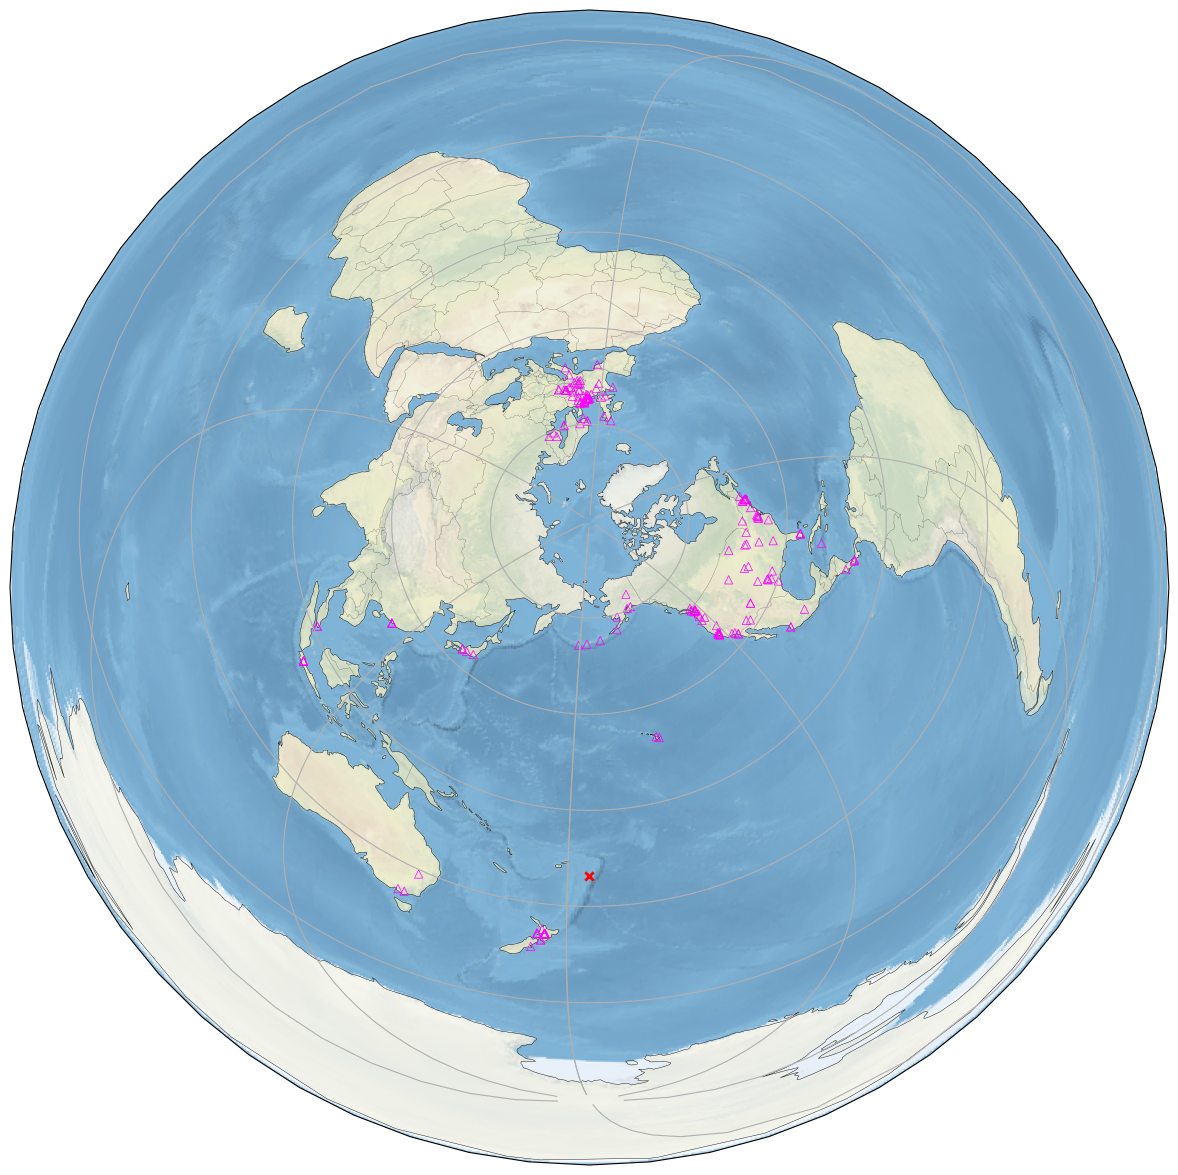

Smallest great cricle distance is 2137.71km. Largest great circle distance is 17687.13km


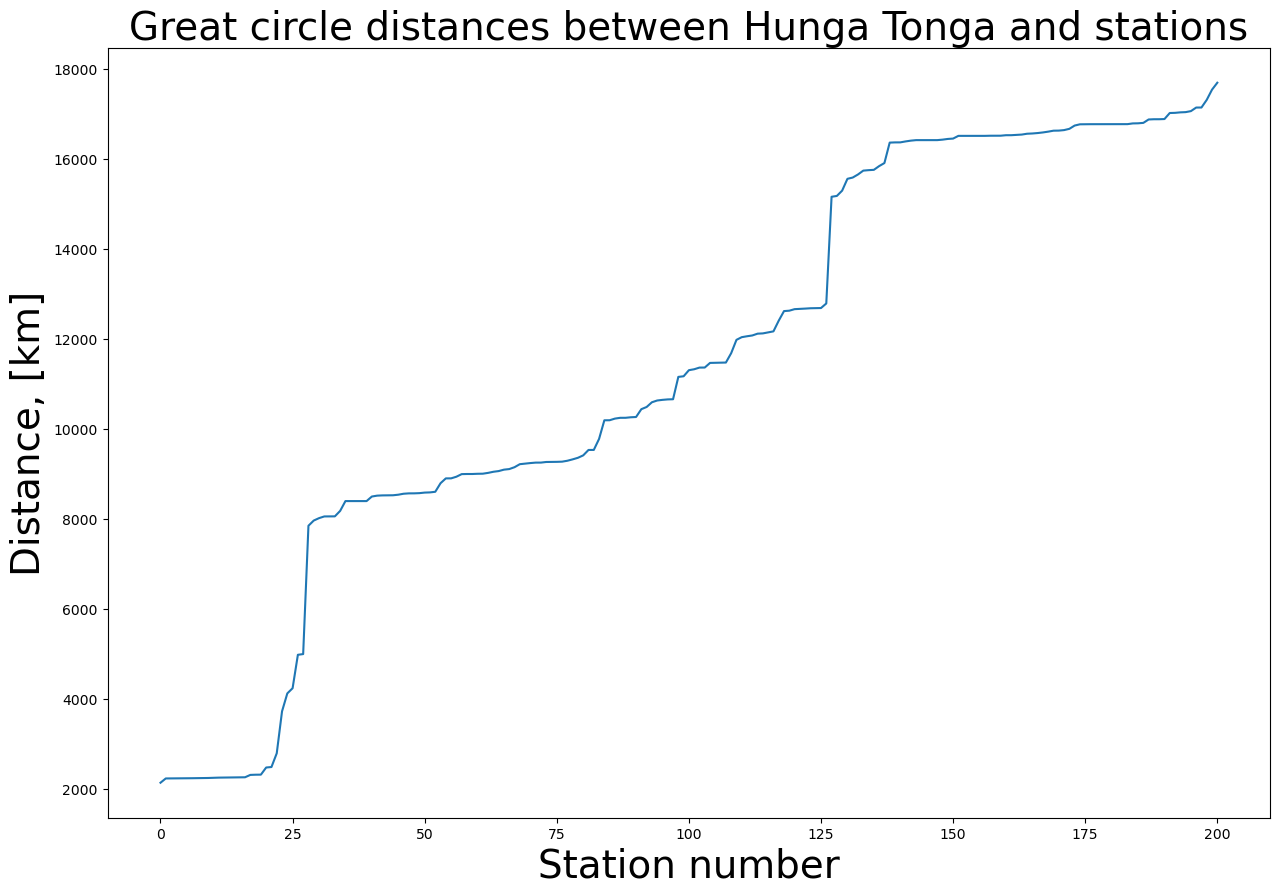

In [ ]:
# Map
plot_map(lats, lons, tonga_latlon)
dists_km = circle_distance(n_files, lats, lons, tonga_latlon)

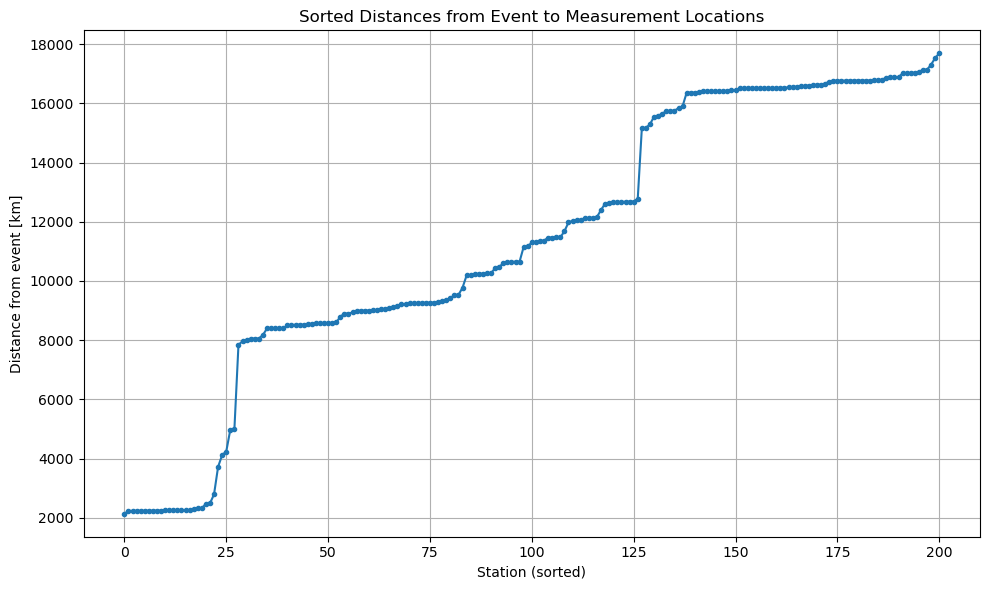

In [ ]:
# Sort distances and plot
sorted_dists = np.sort(dists_km)
plt.figure(figsize=(10, 6))
plt.plot(sorted_dists, marker='o', linestyle='-', markersize=3)
plt.xlabel('Station (sorted)')
plt.ylabel('Distance from event [km]')
plt.title('Sorted Distances from Event to Measurement Locations')
plt.grid(True)
plt.tight_layout()
plt.show()

## Task 2

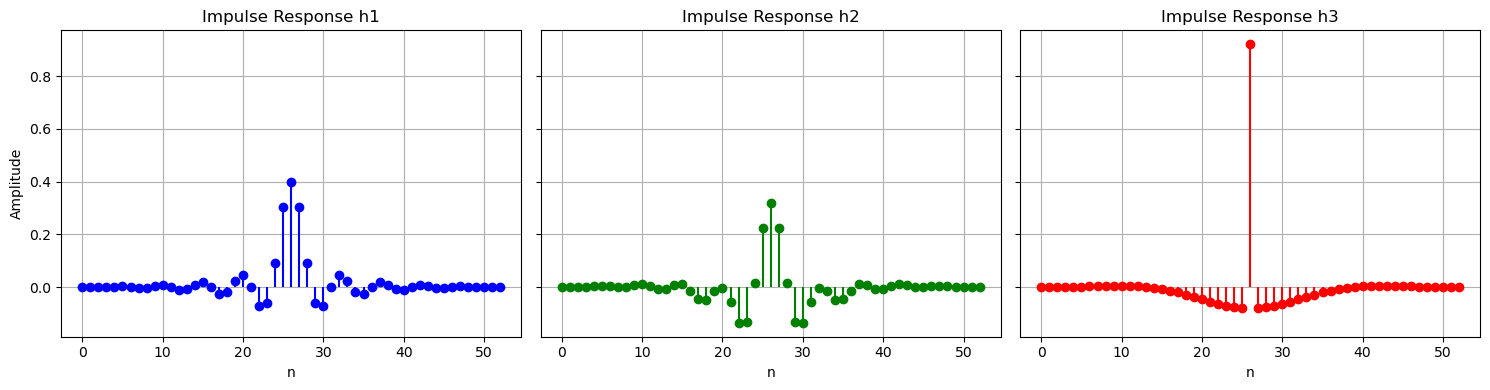

In [ ]:
# Convert lists to numpy arrays for plotting
h1 = np.array(h1)
h2 = np.array(h2)
h3 = np.array(h3)

fig, axs = plt.subplots(1, 3, figsize=(15, 4), sharey=True)

axs[0].stem(h1, linefmt='b-', markerfmt='bo', basefmt=' ')
axs[0].set_title('Impulse Response h1')
axs[0].set_xlabel('n')
axs[0].set_ylabel('Amplitude')
axs[0].grid(True)

axs[1].stem(h2, linefmt='g-', markerfmt='go', basefmt=' ')
axs[1].set_title('Impulse Response h2')
axs[1].set_xlabel('n')
axs[1].grid(True)

axs[2].stem(h3, linefmt='r-', markerfmt='ro', basefmt=' ')
axs[2].set_title('Impulse Response h3')
axs[2].set_xlabel('n')
axs[2].grid(True)

plt.tight_layout()
plt.show()

## 2 b) 
ylenchoice ==1 then the length should be M + N − 1, where M and are the lengths of x[n] and h[n], respectively. For ylen_choice == 0, the output
shall be of the same length as x[n]. Here is my function for convolving the FIR signal.

In [ ]:
def convolve_signal(signal, impulse_response, ylen_choice=0):
    """
    Perform convolution between a signal and an impulse response (from scratch, no np.convolve).
    If ylen_choice == 1, returns full convolution (length n + m - 1).
    If ylen_choice == 0, returns output of length n (same as 'same' mode).
    """
    n = len(signal)
    m = len(impulse_response)
    result_len = n + m - 1
    result = [0.0] * result_len

    for i in range(n):
        for j in range(m):
            result[i + j] += signal[i] * impulse_response[j]

    if ylen_choice == 1:
        return result
    else:
        # Robust centering for 'same' mode
        start = (result_len - n) // 2
        end = start + n
        return result[start:end]


In [ ]:
# Testing convolution function
x = [7,2,5,1,0,3,2]
h = [8,2,3,4,5,6]

y1 = np.convolve(x,h,"same")
y2 = convolve_signal(x,h,0)

print("h1 equal:", np.allclose(y1, y2))


h1 equal: True


In [ ]:

# Convolve using custom function
convolve_my_h1 = convolve_signal(data_collection[0,:], h1, ylen_choice=0)
convolve_my_h2 = convolve_signal(data_collection[0,:], h2, ylen_choice=0)
convolve_my_h3 = convolve_signal(data_collection[0,:], h3, ylen_choice=0)

# Convolve using numpy
convolve_numpy_1 = np.convolve(data_collection[0,:], h1, mode='same')
convolve_numpy_2 = np.convolve(data_collection[0,:], h2, mode='same')
convolve_numpy_3 = np.convolve(data_collection[0,:], h3, mode='same')

# Verify equivalence
print("h1 equal:", np.allclose(convolve_my_h1, convolve_numpy_1))
print("h2 equal:", np.allclose(convolve_my_h2, convolve_numpy_2))
print("h3 equal:", np.allclose(convolve_my_h3, convolve_numpy_3))


h1 equal: True
h2 equal: True
h3 equal: True


## 2 c) Discrete-time Fourier Transform (DTFT)
Here is the function I made for DTFT. The function takes $N$ and $f_s$ as inputs. $N$ is the number of points on the unit circle that are output for $\omega$ and $f_s$ is the sampling frequency. The two outputs of the function are the $H(e^{ij\omega})$ and the frequency vector provided in the m


In [ ]:
def dtft(x, N=1024, fs=1.0, return_magnitude=True):
    """
    Compute the Discrete-Time Fourier Transform (DTFT) of a 1D signal x.
    Args:
        x: input signal (1D array)
        N: number of frequency points (int)
        fs: sampling frequency (Hz, float)
    Returns:
        H: DTFT complex values (length N)
        f: frequency axis in Hz (length N)
    """

    x = np.asarray(x)
    n = np.arange(len(x))
    omega = np.linspace(0, 2 * np.pi, N, endpoint=False)

    H = np.zeros(N, dtype=complex)
    for k in range(N):
        H[k] = np.sum(x * np.exp(-1j * omega[k] * n)) / len(x)
    
    omega = np.linspace(-np.pi, np.pi, N, endpoint=False)
    f = omega * fs / (2 * np.pi)
    if return_magnitude == True:
        return np.abs(H), f
    else: 
        return H, f

d) Display the absolute value of the frequency spectrum of the provided impulse responses
h1[n], h2[n], h3[n]. That is, you shall plot |H1(ejωn)|, |H2(ejωn)|, and |H3(ejωn)| as function of the physical frequency F.

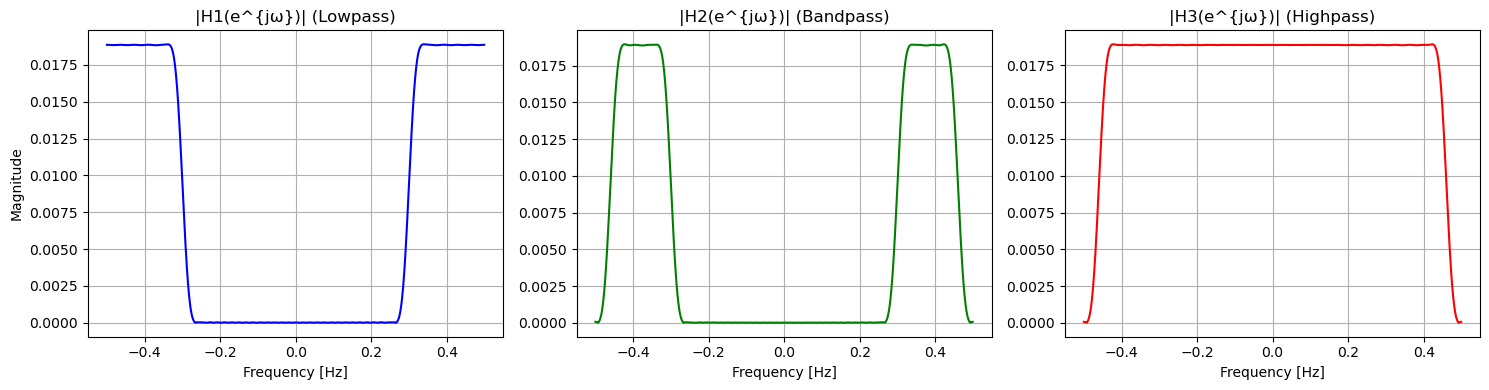

In [ ]:
# Parameters for DTFT
N = 1024  # Number of frequency points
fs = 1    # Set your actual sampling frequency here if known

# Compute DTFT for each impulse response
H1, F1 = dtft(h1, N, fs)
H2, F2 = dtft(h2, N, fs)
H3, F3 = dtft(h3, N, fs)

# Plot the magnitude spectra
plt.figure(figsize=(15, 4))
plt.subplot(1, 3, 1)
plt.plot(F1, np.abs(H1), 'b')
plt.title('|H1(e^{jω})| (Lowpass)')
plt.xlabel('Frequency [Hz]')
plt.ylabel('Magnitude')
plt.grid(True)

plt.subplot(1, 3, 2)
plt.plot(F2, np.abs(H2), 'g')
plt.title('|H2(e^{jω})| (Bandpass)')
plt.xlabel('Frequency [Hz]')
plt.grid(True)

plt.subplot(1, 3, 3)
plt.plot(F3, np.abs(H3), 'r')
plt.title('|H3(e^{jω})| (Highpass)')
plt.xlabel('Frequency [Hz]')
plt.grid(True)

plt.tight_layout()
plt.show()

We see that $h_1$ is a low-pass filter, $h_2$ is a band-pass filter and $h_3$ is a high-pass filter. 

## 2 f) 

In [ ]:
# Filter all 201 input time series using built-in convolution (mode='same')
#print(times_collection)
n_series, n_samples = data_collection.shape
filtered_h1 = np.zeros_like(data_collection)
print(np.shape(filtered_h1))
filtered_h2 = np.zeros_like(data_collection)
filtered_h3 = np.zeros_like(data_collection)

for i in range(n_series):
    # Convolving with filter using numpy convolve
    filtered_h1[i, :] = np.convolve(data_collection[i, :], h1, mode='same')
    filtered_h2[i, :] = np.convolve(data_collection[i, :], h2, mode='same')
    filtered_h3[i, :] = np.convolve(data_collection[i, :], h3, mode='same')

#%% SECTION PLOT FOR BANDPASS FILTERED DATA (0.01 - 2 Hz)
# Parameters
low_f = 0.01  # Hz
high_f = 2.0  # Hz

# Get time axis in seconds (assuming dt is in seconds)
n_samples = filtered_h2.shape[1]
#print(dt)
dt2 = 720000*[0.1]
#print(dt)
time_axis = np.arange(n_samples) * dt
print(time_axis)

# Sort stations by distance for plotting
sort_idx = np.argsort(dists_km)
sorted_dists = np.array(dists_km)[sort_idx]
sorted_filtered_h2 = filtered_h2[sort_idx, :]

(201, 720000)
[0.00000e+00 1.00000e-01 2.00000e-01 ... 7.19997e+04 7.19998e+04
 7.19999e+04]


In [ ]:
print(np.shape(data_collection))

(201, 720000)


## Bandpass filter

In [ ]:
from obspy import read, Stream, Trace

# Create figure
N_files = 200
st = Stream()
# Loop through each file
for i in range(N_files):
 # Using h2 filter for every 100 points
 filtered_data = filtered_h2[i]
 tr = Trace(data=filtered_data)
 tr.stats.delta = dt[0] # Set the sampling interval
 tr.stats.starttime = times_collection[i,0] # Set the start time
 tr.stats.distance = dists_km[i] # Set the distance attribute
 st.append(tr)

# Add labels and title
fig = st.plot(type='section', orientation='horizontal')
fig.savefig("img/section_plot.svg", format='svg')
plt.show()
# Save the figure

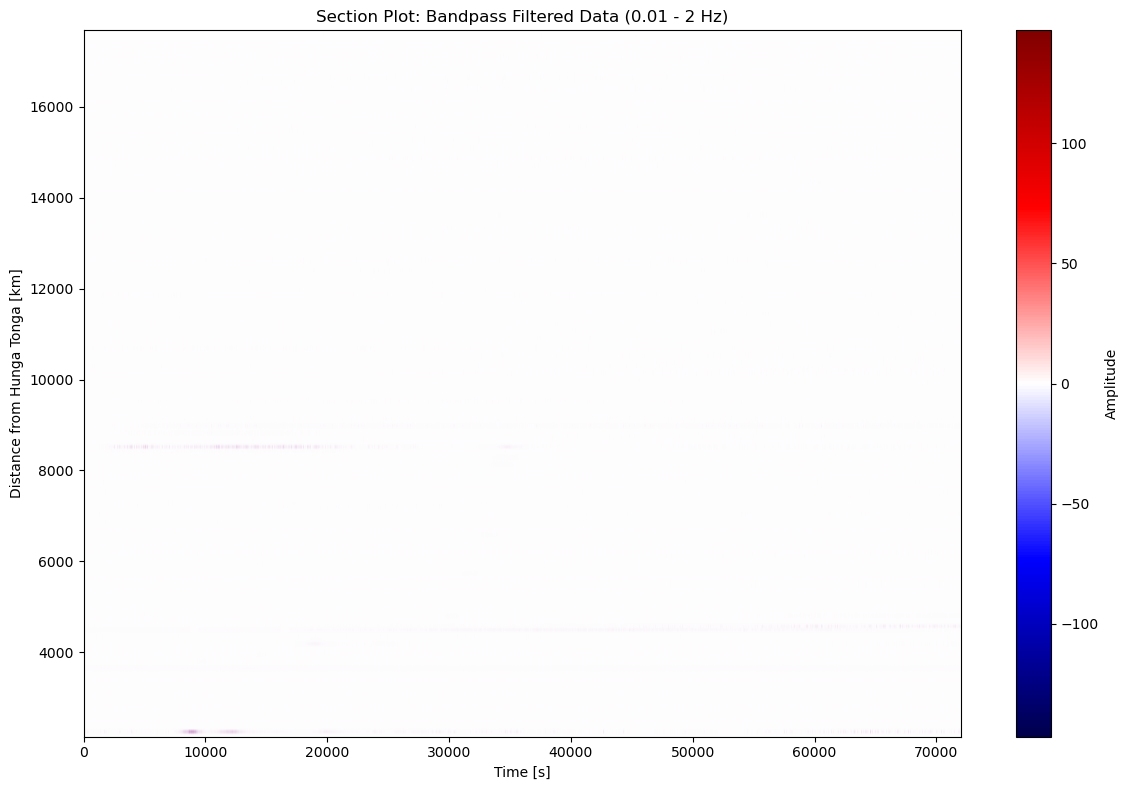

In [ ]:
dt = 720000*[0.1]
# FFT for bandpass filtering in frequency domain
def bandpass_filter_rows(data, fs, low_f, high_f):

    n_stations, n_samples = data.shape # (201 stations, 72000 time points)

    filtered = np.zeros_like(data)

    freqs = np.fft.rfftfreq(n_samples, d=1/fs)
    for i in range(n_stations):
        # Compute 1D DFT discrete Fourier Transform using Fast Fourier Transform (FFT)
        X = np.fft.rfft(data[i])
        # Masking the 
        mask = (freqs >= low_f) & (freqs <= high_f)
        X[~mask] = 0
        filtered[i] = np.fft.irfft(X, n=n_samples)
    return filtered

# Apply bandpass filter
fs = 1/0.1  # Sampling frequency in Hz
bandpassed = bandpass_filter_rows(sorted_filtered_h2, fs, low_f, high_f)

# Plot section plot
plt.figure(figsize=(12, 8))
# defining the bounds of the axes
extent = [time_axis[0], time_axis[-1], sorted_dists[0], sorted_dists[-1]]
plt.imshow(
    bandpassed,
    aspect='auto',
    extent=extent,
    origin='lower',
    cmap='seismic',
    vmin=-np.max(np.abs(bandpassed)),
    vmax=np.max(np.abs(bandpassed))
)
plt.colorbar(label='Amplitude')
plt.xlabel('Time [s]')
plt.ylabel('Distance from Hunga Tonga [km]')
plt.title('Section Plot: Bandpass Filtered Data (0.01 - 2 Hz)')
plt.tight_layout()
plt.show()

IndexError: invalid index to scalar variable.

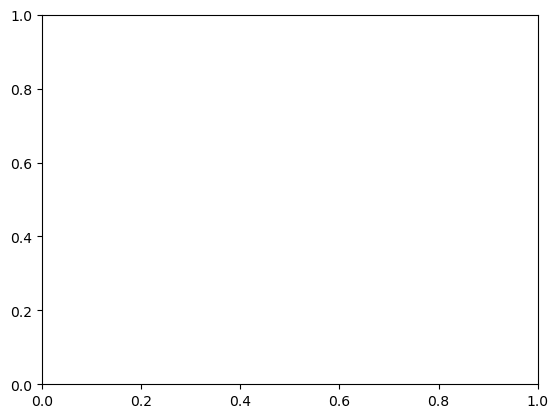

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Create figure
fig, ax = plt.subplots()
N_files = 200
# Loop through each file
for i in range(N_files):
    # Using h2 filter for every 100 points
    filtered_data = filtered_h2[i][::100]
    
    # Scaling variable for visible signal
    scaling = 120 / np.max(filtered_data) * 1000
    
    # Compute y values and convert to km
    y = (filtered_data * scaling + sorted_dists[i]) / 1000
    
    # Time values
    t = time_axis[i][::100]
    
    # Plot with thin black line
    ax.plot(t, y, linewidth=0.01, color='black')

# Add labels and title
ax.set_title("Section plot")
ax.set_xlabel("UTC Time (HH:MM)")
ax.set_ylabel("Distance (km)")

# Save the figure
fig.savefig("figures/section_plot.eps", format='eps')

## Task 3 Estimating the celerity of the globally propagating acoustic wave
### a) 

In [ ]:
def pick_arrival_times(
    data_collection, filtered_h1, filtered_h2, filtered_h3, 
    times_collection, sorted_indices, start_idx, stop_idx, 
    time_axis, save_filename="arrival_picks.npz"
):
    """
    Interactive routine for picking arrival times on sorted station signals.
    Saves picked times and station indices to a file.
    """
    picked_times = []
    picked_station_indices = []

    for idx in range(start_idx, stop_idx):
        station_idx = sorted_indices[idx]
        raw = data_collection[station_idx]
        f1 = filtered_h1[station_idx]
        f2 = filtered_h2[station_idx]
        f3 = filtered_h3[station_idx]

        plt.figure(figsize=(12, 8))
        # 4 subplots
        plt.subplot(4, 1, 1)
        plt.plot(time_axis, raw, 'k')
        plt.title(f'Station {station_idx} (Raw)')
        plt.ylabel('Amplitude')
        plt.grid(True)

        plt.subplot(4, 1, 2)
        plt.plot(time_axis, f1, 'b')
        plt.title('Filtered: h1[n] (Lowpass)')
        plt.ylabel('Amplitude')
        plt.grid(True)

        plt.subplot(4, 1, 3)
        plt.plot(time_axis, f2, 'g')
        plt.title('Filtered: h2[n] (Bandpass)')
        plt.ylabel('Amplitude')
        plt.grid(True)

        plt.subplot(4, 1, 4)
        plt.plot(time_axis, f3, 'r')
        plt.title('Filtered: h3[n] (Highpass)')
        plt.xlabel('Time [s]')
        plt.ylabel('Amplitude')
        plt.grid(True)

        plt.tight_layout()
        plt.suptitle(f"Station {station_idx} (Sorted #{idx})", y=1.02, fontsize=14)
        plt.subplots_adjust(top=0.93)

        print(f"Click on the arrival time for station {station_idx} (sorted #{idx})")
        picked = plt.ginput(1, timeout=-1)
        plt.close()

        if picked:
            picked_time = picked[0][0]  # x-coordinate (time)
            picked_times.append(picked_time)
            picked_station_indices.append(station_idx)
        else:
            picked_times.append(np.nan)
            picked_station_indices.append(station_idx)

        # Save after each pick for safety
        np.savez(
            save_filename, 
            picked_times=np.array(picked_times), 
            picked_station_indices=np.array(picked_station_indices)
        )
        print(f"Saved pick for station {station_idx} at time {picked_times[-1]:.2f} s")

    print(f"Picking session complete. Results saved to {save_filename}.")

In [ ]:
# Sort stations by distance
sort_idx = np.argsort(dists_km)
time_axis = np.arange(filtered_h1.shape[1]) * dt

# Choose start and stop indices for picking session
start_idx = 0
stop_idx = len(sort_idx)  # or any subset, e.g., 0, 10

# Run picking routine
pick_arrival_times(
    data_collection, filtered_h1, filtered_h2, filtered_h3,
    times_collection, sort_idx, start_idx, stop_idx, time_axis,
    save_filename="arrival_picks_session1.npz"
)

ValueError: operands could not be broadcast together with shapes (720000,) (201,) 

## Resources:
